In [1]:
# This cell is removed with the tag: "remove-input"
# As such, it will not be shown in documentation

import warnings
warnings.filterwarnings('ignore')


(Tutorial_Get_bondgraph)=
# Get bondgraph

*Extracting the covalent bond graph of a molecular system.*

The function {func}`molsysmt.chemical_states.get_bondgraph` extracts the network graph of covalent bonds where atoms represent nodes and covalent bonds represent edges.

:::{versionadded} 1.0.0
:::

:::{admonition} API documentation
:class: dropdown

Follow this link for a detailed description of the input arguments, raised errors, and returned objects of this function: {func}`molsysmt.chemical_states.get_bondgraph`.
:::


## Basic usage

Let's show how to extract a network graph representation of covalent bonds for Met-enkephalin:


In [2]:
import molsysmt as msm
import networkx as nx
import matplotlib.pyplot as plt


In [3]:
molsys = msm.convert(msm.systems['Met-enkephalin']['met_enkephalin.h5msm'])


:::{note}
:class: dropdown

**Demo Systems Catalog**

This tutorial uses demonstration datasets provided by MolSysMT. To explore the full catalog of bundled systems, forms, and file paths, visit the {ref}`Demo Systems <user-foundations-entrance-demo-systems>` guide.
:::


We extract the bond graph as a NetworkX graph using {func}`molsysmt.chemical_states.get_bondgraph`:


In [4]:
graph = msm.chemical_states.get_bondgraph(molsys, to_form='networkx.Graph')


In [5]:
n_nodes = graph.number_of_nodes()
n_edges = graph.number_of_edges()
print(f'The graph has {n_nodes} nodes and {n_edges} edges.')


The graph has 72 nodes and 73 edges.


## Visualizing the 2D bond graph

We can render the 2D topology graph using NetworkX and Matplotlib, labeling nodes with their atom names:


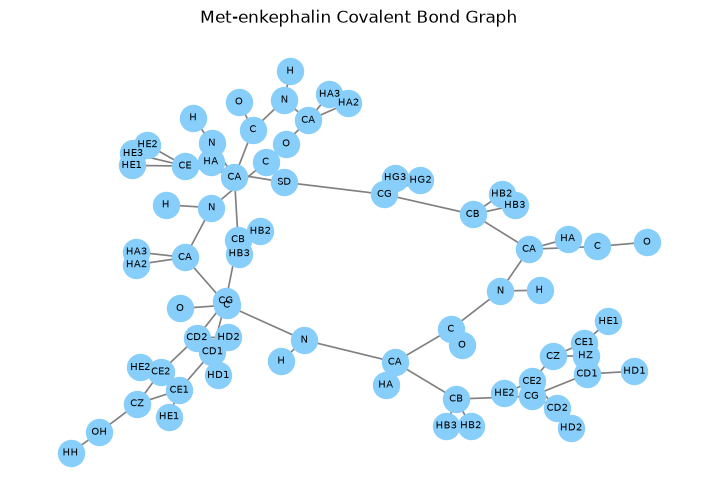

In [6]:
atom_names = msm.get(molsys, element='atom', name=True)
labels = {i: atom_names[i] for i in range(len(atom_names))}

plt.figure(figsize=(9, 6))
pos = nx.spring_layout(graph, seed=42)
nx.draw_networkx_nodes(graph, pos, node_color='lightskyblue', node_size=350)
nx.draw_networkx_edges(graph, pos, edge_color='gray', width=1.2)
nx.draw_networkx_labels(graph, pos, labels=labels, font_size=7)
plt.title('Met-enkephalin Covalent Bond Graph')
plt.axis('off')
plt.show()


## Connected components analysis

We can compute the number of connected covalent components using NetworkX functions:


In [7]:
components = list(nx.connected_components(graph))
print(f'Number of connected covalent components: {len(components)}')


Number of connected covalent components: 1


## Selecting connectivity in a chemical state

Both connectivity tools accept keyword-only `chemical_state` and
`structure_indices`. The reference remains the default; an integer chooses an
explicit state. With `chemical_state='structure'`, selected source structures
must resolve to one known state. Missing associations or multiple states raise;
there is no fallback to reference. Structure indices also constrain spatial
selection. General `get` propagates that same scope to selections and masks.

The graph is induced by the selected atom set: omitted atoms cannot provide
paths between retained atoms. Nodes and returned sets use full source atom
indices, with duplicates removed and blocks ordered by their smallest atom index.
The label array covers the full source atom axis and uses -1 outside selection.
Empty selections return an empty set array or an all-minus-one label array.
These operations inspect stored relationships; they do not infer missing bonds
or certify a partial graph complete. Existing relationship-type behavior remains.
MolSysDict 0.2 and H5MSM 0.5 preserve independent chemical states. TopologyDict
0.2 carries stable inventory only; legacy 0.1 inputs remain readable.

This independent six-atom chain illustrates why filtering full-system component
labels cannot replace induced connectivity:


In [8]:
import numpy as np
import pandas as pd
import molsysmt as msm
from molsysmt.native import MolSys
molsys = MolSys(n_atoms=6)
molsys.chemical_states._set_chemical_state_bonds(pd.DataFrame(dict(atom1_index=[0, 1, 2, 3, 4],
                               atom2_index=[1, 2, 3, 4, 5])))
selected = [5, 1, 0, 3, 1]
graph = msm.chemical_states.get_bondgraph(molsys, selection=selected, chemical_state=0)
assert list(graph.nodes) == [0, 1, 3, 5]
assert list(graph.edges) == [(0, 1)]
labels = msm.chemical_states.get_covalent_blocks(
    molsys, selection=selected, chemical_state=0, output_type='numpy.ndarray')
assert labels.tolist() == [0, 0, -1, 1, -1, 2]
print(labels.tolist())


[0, 0, -1, 1, -1, 2]


:::{seealso}
:class: dropdown

**Related Tools & References**

- {ref}`Convert <Tutorial_Convert>`: Convert molecular systems between different forms with {func}`molsysmt.basic.convert`.
- {ref}`Get <Tutorial_Get>`: Query atom and bond properties with {func}`molsysmt.basic.get`.
- {ref}`Get covalent blocks <Tutorial_Get_covalent_blocks>`: Partition molecular systems into disconnected covalent blocks with {func}`molsysmt.chemical_states.get_covalent_blocks`.
- {ref}`Get covalent paths <Tutorial_Get_covalent_paths>`: Search for covalent bond chains matching sequence patterns with {func}`molsysmt.chemical_states.get_covalent_paths`.
:::
